In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as pt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('NYHousing.csv')
df.head()

,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
0,Brokered by Douglas Elliman -111 Fifth Ave,Condo for sale,315000,2,2.000000,1400.0,2 E 55th St Unit 803,"New York, NY 10022","2 E 55th St Unit 803New York, NY 10022",New York County,New York,Manhattan,East 55th Street,Regis Residence,"Regis Residence, 2 E 55th St #803, New York, N...",40.761255,-73.974483
1,Brokered by Serhant,Condo for sale,195000000,7,10.000000,17545.0,Central Park Tower Penthouse-217 W 57th New Yo...,"New York, NY 10019",Central Park Tower Penthouse-217 W 57th New Yo...,United States,New York,New York County,New York,West 57th Street,"217 W 57th St, New York, NY 10019, USA",40.766393,-73.980991
2,Brokered by Sowae Corp,House for sale,260000,4,2.000000,2015.0,620 Sinclair Ave,"Staten Island, NY 10312","620 Sinclair AveStaten Island, NY 10312",United States,New York,Richmond County,Staten Island,Sinclair Avenue,"620 Sinclair Ave, Staten Island, NY 10312, USA",40.541805,-74.196109
3,Brokered by COMPASS,Condo for sale,69000,3,1.000000,445.0,2 E 55th St Unit 908W33,"Manhattan, NY 10022","2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York,New York County,New York,East 55th Street,"2 E 55th St, New York, NY 10022, USA",40.761398,-73.974613
4,Brokered by Sotheby's International Realty - E...,Townhouse for sale,55000000,7,2.373861,14175.0,5 E 64th St,"New York, NY 10065","5 E 64th StNew York, NY 10065",United States,New York,New York County,New York,East 64th Street,"5 E 64th St, New York, NY 10065, USA",40.767224,-73.969856


In [3]:
df.shape

(4801, 17)

In [4]:
df.dtypes

BROKERTITLE                     object
TYPE                            object
PRICE                            int64
BEDS                             int64
BATH                           float64
PROPERTYSQFT                   float64
ADDRESS                         object
STATE                           object
MAIN_ADDRESS                    object
ADMINISTRATIVE_AREA_LEVEL_2     object
LOCALITY                        object
SUBLOCALITY                     object
STREET_NAME                     object
LONG_NAME                       object
FORMATTED_ADDRESS               object
LATITUDE                       float64
LONGITUDE                      float64
dtype: object

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4801 entries, 0 to 4800
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   BROKERTITLE                  4801 non-null   object 
 1   TYPE                         4801 non-null   object 
 2   PRICE                        4801 non-null   int64  
 3   BEDS                         4801 non-null   int64  
 4   BATH                         4801 non-null   float64
 5   PROPERTYSQFT                 4801 non-null   float64
 6   ADDRESS                      4801 non-null   object 
 7   STATE                        4801 non-null   object 
 8   MAIN_ADDRESS                 4801 non-null   object 
 9   ADMINISTRATIVE_AREA_LEVEL_2  4801 non-null   object 
 10  LOCALITY                     4801 non-null   object 
 11  SUBLOCALITY                  4801 non-null   object 
 12  STREET_NAME                  4801 non-null   object 
 13  LONG_NAME         

In [6]:
df.describe()

,PRICE,BEDS,BATH,PROPERTYSQFT,LATITUDE,LONGITUDE
count,4.801000e+03,4801.000000,4801.000000,4801.000000,4801.000000,4801.000000
mean,2.356940e+06,3.356801,2.373861,2184.207862,40.714227,-73.941601
std,3.135525e+07,2.602315,1.946962,2377.140894,0.087676,0.101082
min,2.494000e+03,1.000000,0.000000,230.000000,40.499546,-74.253033
25%,4.990000e+05,2.000000,1.000000,1200.000000,40.639375,-73.987143
50%,8.250000e+05,3.000000,2.000000,2184.207862,40.726749,-73.949189
75%,1.495000e+06,4.000000,3.000000,2184.207862,40.771923,-73.870638
max,2.147484e+09,50.000000,50.000000,65535.000000,40.912729,-73.702450


In [7]:
df.isna().sum()

BROKERTITLE                    0
TYPE                           0
PRICE                          0
BEDS                           0
BATH                           0
PROPERTYSQFT                   0
ADDRESS                        0
STATE                          0
MAIN_ADDRESS                   0
ADMINISTRATIVE_AREA_LEVEL_2    0
LOCALITY                       0
SUBLOCALITY                    0
STREET_NAME                    0
LONG_NAME                      0
FORMATTED_ADDRESS              0
LATITUDE                       0
LONGITUDE                      0
dtype: int64

In [8]:
dupes=df.duplicated().sum()
print(dupes)

214


In [9]:
df[df.duplicated(keep=False)]

,BROKERTITLE,TYPE,PRICE,BEDS,BATH,PROPERTYSQFT,ADDRESS,STATE,MAIN_ADDRESS,ADMINISTRATIVE_AREA_LEVEL_2,LOCALITY,SUBLOCALITY,STREET_NAME,LONG_NAME,FORMATTED_ADDRESS,LATITUDE,LONGITUDE
80,Brokered by Douglas Elliman - 575 Madison Ave,Condo for sale,1650000,2,2.000000,1065.000000,200 E 94th St Apt 414,"New York, NY 10128","200 E 94th St Apt 414New York, NY 10128",New York,New York County,New York,Manhattan,200,"200 E 94th St APT 414, New York, NY 10128, USA",40.783355,-73.949998
81,Brokered by Douglas Elliman - 575 Madison Ave,Condo for sale,1650000,2,2.000000,1065.000000,200 E 94th St Apt 414,"New York, NY 10128","200 E 94th St Apt 414New York, NY 10128",New York,New York County,New York,Manhattan,200,"200 E 94th St APT 414, New York, NY 10128, USA",40.783355,-73.949998
113,Brokered by Sowae Corp,House for sale,400000,4,2.000000,1980.000000,781 Sheperd Ave,"Brooklyn, NY 11208","781 Sheperd AveBrooklyn, NY 11208",United States,New York,Kings County,Brooklyn,Shepherd Avenue,"781 Shepherd Ave, Brooklyn, NY 11208, USA",40.665357,-73.877087
114,Brokered by Sowae Corp,Multi-family home for sale,346000,5,2.000000,2184.207862,103-12 104th St,"Ozone Park, NY 11417","103-12 104th StOzone Park, NY 11417",United States,New York,Queens County,Queens,104th Street,"103-12 104th St, Jamaica, NY 11417, USA",40.683789,-73.838104
115,Brokered by Sowae Corp,House for sale,400000,4,2.000000,1980.000000,781 Sheperd Ave,"Brooklyn, NY 11208","781 Sheperd AveBrooklyn, NY 11208",United States,New York,Kings County,Brooklyn,Shepherd Avenue,"781 Shepherd Ave, Brooklyn, NY 11208, USA",40.665357,-73.877087
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4760,NoBroker,Multi-family home for sale,2000000,8,2.373861,2184.207862,2324 60th St,"Brooklyn, NY 11204","2324 60th StBrooklyn, NY 11204",United States,New York,Kings County,Brooklyn,60th Street,"2324 60th St, Brooklyn, NY 11204, USA",40.614758,-73.975714
4770,Brokered by Sotheby's International Realty - E...,Condo for sale,2600000,3,2.000000,1729.000000,242 E 15th St Apt 1,"New York, NY 10003","242 E 15th St Apt 1New York, NY 10003",New York,New York County,New York,Manhattan,242,"242 E 15th St APT 1, New York, NY 10003, USA",40.733031,-73.985037
4775,Brokered by EXIT REALTY PREMIER,House for sale,749000,3,2.373861,2002.000000,631 Essex St,"Brooklyn, NY 11208","631 Essex StBrooklyn, NY 11208",United States,New York,Kings County,Brooklyn,Essex Street,"631 Essex St, Brooklyn, NY 11208, USA",40.668173,-73.880027
4780,NoBroker,Multi-family home for sale,2000000,8,2.373861,2184.207862,2324 60th St,"Brooklyn, NY 11204","2324 60th StBrooklyn, NY 11204",United States,New York,Kings County,Brooklyn,60th Street,"2324 60th St, Brooklyn, NY 11204, USA",40.614758,-73.975714


In [10]:
df1=df.drop_duplicates()

In [11]:
df1.shape

(4587, 17)

In [12]:
df1.columns=df1.columns.str.lower()
df1.columns

Index(['brokertitle', 'type', 'price', 'beds', 'bath', 'propertysqft',
       'address', 'state', 'main_address', 'administrative_area_level_2',
       'locality', 'sublocality', 'street_name', 'long_name',
       'formatted_address', 'latitude', 'longitude'],
      dtype='object')

{'whiskers': [<matplotlib.lines.Line2D at 0x16774e28050>,
 'caps': [<matplotlib.lines.Line2D at 0x16774e282d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x16773b93d90>],
 'medians': [<matplotlib.lines.Line2D at 0x16774e28550>],
 'fliers': [<matplotlib.lines.Line2D at 0x16774e28690>],
 'means': []}

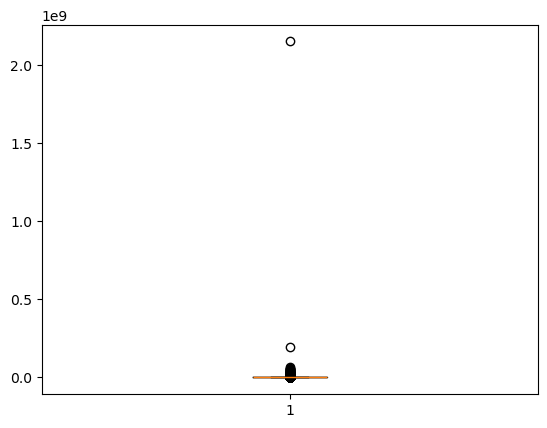

In [13]:
pt.boxplot(df1['price'])


In [14]:
q3=df1['price'].quantile(.75)
q1=df1['price'].quantile(.25)
IQR=q3-q1
upper=df1['price'].quantile(.75)+1.5*IQR
lower=df1['price'].quantile(.25)-1.5*IQR
df1['price']=np.where(df1['price']>upper,upper,np.where(df1['price']<lower,df1['price'].min(),df1['price']))

In [15]:
df1=pd.get_dummies(df1,columns=['state','locality','type'],drop_first=True,dtype=int)

In [16]:
df1.head()

,brokertitle,price,beds,bath,propertysqft,address,main_address,administrative_area_level_2,sublocality,street_name,...,type_Condop for sale,type_Contingent,type_For sale,type_Foreclosure,type_House for sale,type_Land for sale,type_Mobile house for sale,type_Multi-family home for sale,type_Pending,type_Townhouse for sale
0,Brokered by Douglas Elliman -111 Fifth Ave,315000.0,2,2.000000,1400.0,2 E 55th St Unit 803,"2 E 55th St Unit 803New York, NY 10022",New York County,Manhattan,East 55th Street,...,0,0,0,0,0,0,0,0,0,0
1,Brokered by Serhant,2997750.0,7,10.000000,17545.0,Central Park Tower Penthouse-217 W 57th New Yo...,Central Park Tower Penthouse-217 W 57th New Yo...,United States,New York County,New York,...,0,0,0,0,0,0,0,0,0,0
2,Brokered by Sowae Corp,260000.0,4,2.000000,2015.0,620 Sinclair Ave,"620 Sinclair AveStaten Island, NY 10312",United States,Richmond County,Staten Island,...,0,0,0,0,1,0,0,0,0,0
3,Brokered by COMPASS,69000.0,3,1.000000,445.0,2 E 55th St Unit 908W33,"2 E 55th St Unit 908W33Manhattan, NY 10022",United States,New York County,New York,...,0,0,0,0,0,0,0,0,0,0
4,Brokered by Sotheby's International Realty - E...,2997750.0,7,2.373861,14175.0,5 E 64th St,"5 E 64th StNew York, NY 10065",United States,New York County,New York,...,0,0,0,0,0,0,0,0,0,1


In [17]:
df1.columns

Index(['brokertitle', 'price', 'beds', 'bath', 'propertysqft', 'address',
       'main_address', 'administrative_area_level_2', 'sublocality',
       'street_name',
       ...
       'type_Condop for sale', 'type_Contingent', 'type_For sale',
       'type_Foreclosure', 'type_House for sale', 'type_Land for sale',
       'type_Mobile house for sale', 'type_Multi-family home for sale',
       'type_Pending', 'type_Townhouse for sale'],
      dtype='object', length=343)

In [18]:
df1['logprice']=np.log(df1['price'])
df1['logsqft']=np.log(df1['propertysqft'])
df1['bathperbed']=df1['bath']/df1['beds']
dat=df1.drop(columns=['price','beds','brokertitle','address','main_address','administrative_area_level_2','sublocality','street_name','long_name','formatted_address','latitude','longitude'])
dat.head()

,bath,propertysqft,"state_Astoria, NY 11101","state_Astoria, NY 11102","state_Astoria, NY 11103","state_Astoria, NY 11105","state_Astoria, NY 11106","state_Bayside, NY 11360","state_Bayside, NY 11361","state_Bayside, NY 11364",...,type_Foreclosure,type_House for sale,type_Land for sale,type_Mobile house for sale,type_Multi-family home for sale,type_Pending,type_Townhouse for sale,logprice,logsqft,bathperbed
0,2.000000,1400.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,12.660328,7.244228,1.000000
1,10.000000,17545.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,14.913373,9.772524,1.428571
2,2.000000,2015.0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,12.468437,7.608374,0.500000
3,1.000000,445.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,11.141862,6.098074,0.333333
4,2.373861,14175.0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,14.913373,9.559235,0.339123


In [19]:
dat.shape

(4587, 334)

In [20]:
x=dat.drop(columns=['logprice'])
y=dat['logprice']

In [21]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=.2,random_state=0)

In [22]:
scaler=StandardScaler()

In [23]:
scaled_xtrain=scaler.fit_transform(xtrain)
scaled_xtest=scaler.transform(xtest)

In [24]:
mod1=LinearRegression()
mod2=Lasso(alpha=.5,max_iter=100,tol=.1)
mod3=Ridge(alpha=.5,max_iter=100,tol=.1)

In [25]:
mod1.fit(scaled_xtrain,ytrain)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [26]:
mod1.predict(scaled_xtest)

array([13.20138487, 13.54509234, 13.41752836, 14.00037744, 14.24672038,
       13.78359347, 14.15823717, 12.46575287, 13.08963011, 13.5558684 ,
       14.3899163 , 13.72553334, 14.22020257, 14.4338127 , 12.83434812,
       13.53155255, 13.53154701, 13.60030081, 13.79494922, 14.84543863,
       12.78687476, 13.28488422, 14.55427655, 12.57012437, 14.39508337,
       13.3855173 , 13.60874408, 14.18892932, 14.01110516, 13.16390202,
       13.70037026, 13.3909379 , 13.83728153, 13.16311652, 13.69401063,
       14.38101694, 13.50078178, 14.28300257, 13.77270377, 12.95316501,
       15.49579761, 13.01745223, 13.2649246 , 12.67449797, 13.74174582,
       12.26028017, 13.92489271, 13.75795497, 14.91424809, 13.1634069 ,
       13.36757288, 12.61068237, 13.89407766, 13.94751588, 12.27874845,
       14.2208474 , 14.82696478, 13.8924598 , 12.71409912, 13.97483285,
       14.21596419, 13.60090793, 13.48030077, 13.49114978, 13.75130166,
       13.9889149 , 14.29519429, 16.38743558, 13.16317699, 12.85

In [27]:
mod1.score(scaled_xtest,ytest)

0.6550083011785648

In [28]:
mod2.fit(scaled_xtrain,ytrain)


,alpha,0.5
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,100
,tol,0.1
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [29]:
mod3.fit(scaled_xtrain,ytrain)


,alpha,0.5
,fit_intercept,True
,copy_X,True
,max_iter,100
,tol,0.1
,solver,'auto'
,positive,False
,random_state,None


In [30]:
mod2.score(scaled_xtest,ytest)

-0.000933894958571102

In [31]:
mod3.score(scaled_xtest,ytest)

0.6554163227115621

In [32]:
import statsmodels.api as sm
X=sm.add_constant(x)
p=sm.OLS(y,X).fit()
print(p.summary())

                            OLS Regression Results                            
Dep. Variable:               logprice   R-squared:                       0.720
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     32.98
Date:                Tue, 21 Jul 2026   Prob (F-statistic):               0.00
Time:                        15:59:31   Log-Likelihood:                -2659.7
No. Observations:                4587   AIC:                             5985.
Df Residuals:                    4254   BIC:                             8127.
Df Model:                         332                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

In [35]:
print(p.pvalues)

const                              2.959698e-272
bath                                1.726449e-52
propertysqft                        1.227167e-15
state_Astoria, NY 11101             2.278786e-01
state_Astoria, NY 11102             1.256806e-01
                                       ...      
type_Multi-family home for sale     8.440636e-63
type_Pending                        4.787763e-18
type_Townhouse for sale             2.666175e-40
logsqft                            2.623336e-115
bathperbed                          1.356602e-01
Length: 334, dtype: float64
